# 00 · Wind→Qlib 数据工程（示范）

这个 notebook 用 **「讲解 + 可运行代码 + 真实输出 + 图表」** 的方式，带你看清**数据工程这一层每个部分在干什么**。

> 这是全流程学习的第 0 层：把 Wind 原始数据，变成可被 Qlib 直接使用的标准数据。后面的因子挖掘、模型、组合、回测都建立在它之上。
>
> **怎么用这个 notebook**：从上到下阅读，每个代码框都可以自己改、自己重跑；`In [ ]` 是代码，下面是它的真实输出。

## 一、整体流程图

In [1]:
from IPython.display import HTML
HTML("""
<div style='display:flex;align-items:stretch;flex-wrap:wrap;gap:6px;font-family:Segoe UI,Microsoft YaHei;font-size:12.5px;'>
  <div style='padding:9px 11px;background:#eef2ff;border:1px solid #c7d2fe;border-radius:8px;width:96px;'>① 全A股票池<br><b>w.wset</b></div>
  <div style='align-self:center;color:#94a3b8;font-size:16px;'>→</div>
  <div style='padding:9px 11px;background:#eff6ff;border:1px solid #bfdbfe;border-radius:8px;width:104px;'>② 分钟数据(不复权)<br><b>w.wsi</b></div>
  <div style='align-self:center;color:#94a3b8;font-size:16px;'>→</div>
  <div style='padding:9px 11px;background:#f0fdfa;border:1px solid #99f6e4;border-radius:8px;width:104px;'>③ 复权因子<br><b>w.wsd</b></div>
  <div style='align-self:center;color:#94a3b8;font-size:16px;'>→</div>
  <div style='padding:9px 11px;background:#f0fdf4;border:1px solid #bbf7d0;border-radius:8px;width:118px;'>④ 组装后复权<br><b>价×factor</b></div>
  <div style='align-self:center;color:#94a3b8;font-size:16px;'>→</div>
  <div style='padding:9px 11px;background:#fff7ed;border:1px solid #fed7aa;border-radius:8px;width:110px;'>⑤ Qlib bin<br><b>dump_bin</b></div>
</div>
""")

## 二、每个模块在干什么

代码被拆成小模块，每个模块只负责一件事。先看全局，再看细节：

In [2]:
import pandas as pd
pd.set_option('display.max_colwidth', 60)
mods = pd.DataFrame([
    ["config.py",        "全局配置：路径、股票池、时间范围、限频、字段"],
    ["run_all.py",       "一键串起下面 5 步（支持 --limit/--start）"],
    ["qdata/wind.py",    "Wind 连接、断线重连、限频、失败重试"],
    ["qdata/universe.py","获取全 A 股票池；Wind 代码 ↔ Qlib 代码转换"],
    ["qdata/minute.py",  "w.wsi 拉分钟数据，按年度分块、断点续传"],
    ["qdata/adjfactor.py","w.wsd 批量拉复权因子"],
    ["qdata/build.py",   "组装后复权 CSV，并调用 dump_bin"],
    ["qdata/dump_bin.py","官方脚本：CSV → Qlib .bin"],
    ["verify_read.py",   "数据健康检查（回读验证）"],
], columns=["文件 / 模块", "用途"])
mods.style.hide(axis='index')

文件 / 模块,用途
config.py,全局配置：路径、股票池、时间范围、限频、字段
run_all.py,一键串起下面 5 步（支持 --limit/--start）
qdata/wind.py,Wind 连接、断线重连、限频、失败重试
qdata/universe.py,获取全 A 股票池；Wind 代码 ↔ Qlib 代码转换
qdata/minute.py,w.wsi 拉分钟数据，按年度分块、断点续传
qdata/adjfactor.py,w.wsd 批量拉复权因子
qdata/build.py,组装后复权 CSV，并调用 dump_bin
qdata/dump_bin.py,官方脚本：CSV → Qlib .bin
verify_read.py,数据健康检查（回读验证）


## 三、配置：所有参数都在一处

`config.py` 集中管理路径、股票池、时间范围和限频，改参数不用翻代码。

In [3]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import config
print("Qlib 频率标识 :", config.FREQ)
print("全A板块 ID    :", config.ALL_A_SECTOR_ID)
print("回溯起点      :", config.START_DATE)
print("wsi 分块月数  :", config.CHUNK_MONTHS)
print("原始分钟字段  :", config.MINUTE_FIELDS)
print("写入Qlib字段  :", config.QLIB_FIELDS)
print("限频间隔(秒)  :", config.WIND_SLEEP)

Qlib 频率标识 : 1min
全A板块 ID    : a001010100000000
回溯起点      : 2023-01-01
wsi 分块月数  : 12
原始分钟字段  : open,high,low,close,volume,amt
写入Qlib字段  : ['open', 'close', 'high', 'low', 'volume', 'factor']
限频间隔(秒)  : 0.35


## 四、股票池：全 A 是哪些股票

第 1 步用 `w.wset` 把全 A 成分拉下来存成 CSV。这里直接读结果（小样本验证时生成的是全量股票池文件）。

In [4]:
uni = pd.read_csv(config.UNIVERSE_FILE)
print("全 A 股票数量 :", len(uni))
print("列名          :", list(uni.columns))
uni.head()

全 A 股票数量 : 5577
列名          : ['wind_code', 'qlib_code', 'name']


,wind_code,qlib_code,name
0,000001.SZ,sz000001,平安银行
1,000002.SZ,sz000002,万科A
2,000006.SZ,sz000006,深振业A
3,000007.SZ,sz000007,全新好
4,000008.SZ,sz000008,神州高铁


## 五、读回 Qlib 数据：确认 bin 能用

第 5 步产出的 `.bin` 是 Qlib 的高效存储格式。这里用 Qlib 官方接口读回：
- **calendar**：所有交易分钟点（时间轴）；
- **instruments**：有哪些股票；
- **features**：每只股票、每个分钟点的各字段。

In [5]:
import qlib
from qlib.data import D

# Windows 下用 threading 后端，避免多进程报 'Please run qlib.init() first'
qlib.init(provider_uri=str(config.QLIB_DATA_DIR), joblib_backend='threading')

cal = D.calendar(freq='1min')
inst = D.instruments(market='all')
codes = D.list_instruments(instruments=inst, as_list=True, freq='1min')

print("calendar 分钟点 :", len(cal), "｜", cal[0], "~", cal[-1])
print("instruments     :", codes)

fields = ['$open', '$close', '$high', '$low', '$volume', '$factor']
df = D.features(codes, fields, freq='1min')
print("features 形状   :", df.shape)
df.head()

[24180:MainThread](2026-10-29 15:56:35,480) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[24180:MainThread](2026-10-29 15:56:37,506) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[24180:MainThread](2026-10-29 15:56:37,508) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_data')}


calendar 分钟点 : 8761 ｜ 2026-09-01 09:30:00 ~ 2026-10-29 11:30:00
instruments     : ['SZ000001', 'SZ000002', 'SZ000006']
features 形状   : (26282, 6)


$open       $close        $high  \
instrument datetime                                                     
SZ000001   2026-09-01 09:30:00   996.649475   996.649475   999.209351   
           2026-09-01 09:31:00   996.649475  1001.769287  1003.475830   
           2026-09-01 09:32:00  1001.769287  1001.769287  1002.622559   
           2026-09-01 09:33:00  1002.622559  1003.475830  1004.329163   
           2026-09-01 09:34:00  1003.475830  1005.182434  1005.182434   

                                       $low    $volume    $factor  
instrument datetime                                                
SZ000001   2026-09-01 09:30:00   994.089600  2729700.0  85.329582  
           2026-09-01 09:31:00   996.649475  2222400.0  85.329582  
           2026-09-01 09:32:00  1001.769287  1117700.0  85.329582  
           2026-09-01 09:33:00  1002.622559  1430700.0  85.329582  
           2026-09-01 09:34:00  1003.475830  1012000.0  85.329582

## 六、验证数据正确性：价格对不对

**口径**：`不复权价 × adjfactor = 后复权价`。所以 `后复权价 / factor` 应当还原成真实股价（平安银行约 11 元）。

In [6]:
import numpy as np
last = df.xs('SZ000001', level='instrument').dropna().tail(1)
c, f = float(last['$close'].iloc[0]), float(last['$factor'].iloc[0])
print("后复权收盘 :", round(c, 2))
print("复权因子   :", round(f, 4))
print("close/factor =", round(c / f, 2), "  <- 应≈ 11.31（真实股价）")
print("NaN 总数   :", int(df.isna().sum().sum()), "（个股停牌/原始 bar 偶发缺失，对齐后为 NaN）")

后复权收盘 : 995.93
复权因子   : 87.2091
close/factor = 11.42   <- 应≈ 11.31（真实股价）
NaN 总数   : 462 （个股停牌/原始 bar 偶发缺失，对齐后为 NaN）


把后复权分钟收盘价画出来，直观检查有没有异常断点（平直段通常是停牌或缺失）：

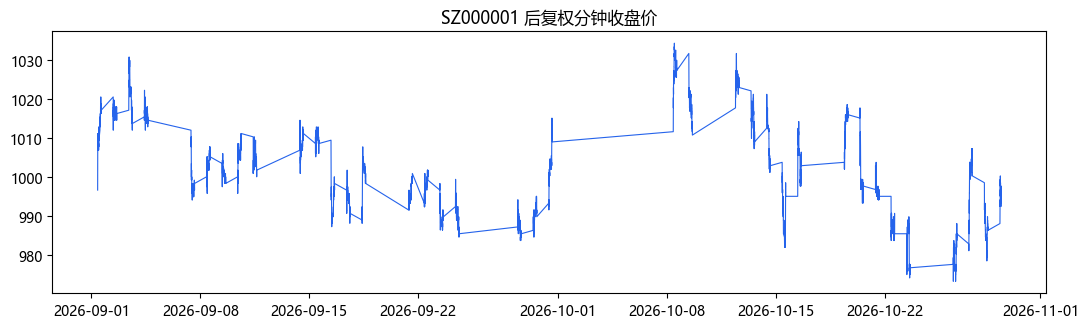

In [7]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

s = df.xs('SZ000001', level='instrument')['$close']
plt.figure(figsize=(11, 3.4))
plt.plot(s.index, s.values, lw=0.8, color='#2563eb')
plt.title('SZ000001 后复权分钟收盘价')
plt.tight_layout(); plt.show()

## 小结与面试要点

**这一层你应该能讲清楚：**
- **数据口径**：用「不复权价 × adjfactor = 后复权价」，volume 保持原始，factor 字段存复权因子；与 Qlib 官方口径一致。
- **为什么后复权**：保证历史价格序列连续可比，因子（如收益率）才不会在除权日出现假跳空。
- **收盘集合竞价**：14:57–15:00 只在 15:00 出一根 bar，14:58/14:59 是占位空行，已剔除。
- **NaN 来源**：个股停牌、原始 bar 偶发缺失（如个别日缺 11:30），对齐到统一日历后为 NaN，下游用 ffill 处理。
- **幸存者偏差**：当前是「指定日期在市全 A」，不含已退市股；严格研究需额外拉历史成分与退市股。

**面试可能追问**：复权因子怎么算？前复权 vs 后复权区别？为什么会有幸存者偏差？分钟数据怎么对齐？——这些都能在这一层回答。

---
下一层 → **阶段 1：单因子研究全流程**（在这套数据上手工实现因子、做 IC/分层/中性化）。